<a href="https://colab.research.google.com/github/nuruyar/ai_master_computervision/blob/main/lab_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from PIL import Image
from pylab import *
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.ndimage as snd
from scipy.ndimage import *
from skimage.feature import (match_descriptors, corner_harris, corner_peaks, ORB, plot_matched_features)
from skimage.color import rgb2gray
from skimage import data
from skimage import transform as tf

import cv2
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


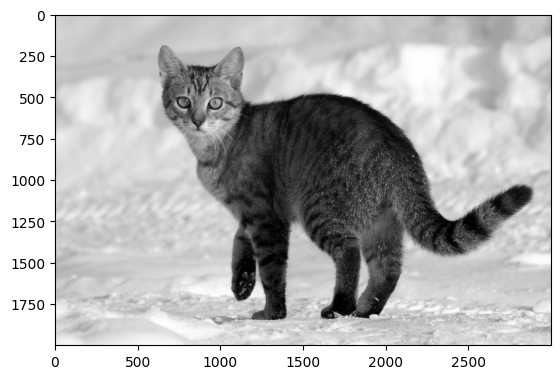

uint8
float64


In [ ]:
path = "/content/drive/MyDrive/Colab Notebooks/Bilgisayarla Görme"
im_color = np.array(Image.open(path + "/kedi.jpeg"))
im_gray = np.array(Image.open(path + "/kedi.jpeg").convert('L'), np.float64)
imgplot = plt.imshow(im_gray, cmap='gray')
plt.show()
print(str(im_color.dtype))
print(str(im_gray.dtype))
img1_cat = cv2.imread(path + "/kedi.jpeg")
img2_cat = cv2.imread(path + "/kedi.jpeg")

**TRANSFORMATIONS**

In [ ]:
def plot_transformed(img, transformed):
  plt.subplot(121),plt.imshow(img, cmap = 'gray')
  plt.title('Original'),plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(transformed, cmap = 'gray')
  plt.title('Transformed'), plt.xticks([]), plt.yticks([])
  plt.show()

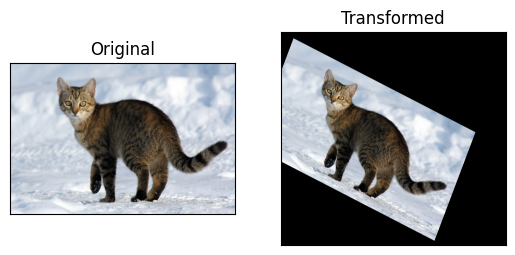

In [ ]:
img = img1_cat
sx = 0.25
sy = 0.75
tx = 200
ty = 100
rotAmount = np.pi/6;
translation_matrix = np.float32([[1, 0, tx], [0, 1, ty], [0,0,1]])
translation_matrix_neg = np.float32(([1,0,-tx],[1,0,-ty],[0,0,1]))
shear_matrix = np.float32([[1, 0.2, 0], [0, 1, 0], [0,0,1]])
scale_matrix = np.float32([[sx, 0, 0],[0, sy, 0], [0,0,1]])
rotation_matrix = np.float32(([np.cos(rotAmount), -np.sin(rotAmount), 0], [np.sin(rotAmount), np.cos(rotAmount), 0], [0,0,1]))
combined_matrix = np.float32(([1,0,0],[0,1,0],[0,0,1]))
combined_matrix = np.matmul(rotation_matrix, combined_matrix)
# combined_matrix = np.matmul(scale_matrix, combined_matrix)
combined_matrix = np.matmul(shear_matrix, combined_matrix)
combined_matrix = np.matmul(translation_matrix, combined_matrix)
# combined_matrix = np.matmul(translation_matrix,combined_matrix)
combined_matrix =  combined_matrix[0:2,:]
transformed = cv2.warpAffine(img,combined_matrix, (int(img.shape[1] * 1.2), int(img.shape[0] * 1.7)))
plot_transformed(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cv2.cvtColor(transformed, cv2.COLOR_BGR2RGB))

**AFFINE TRANSFORM**

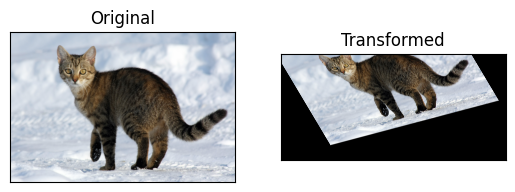

In [ ]:
pts1 = np.float32([[50,50],[200,50],[50,200]])
pts2 = np.float32([[10,100],[200,50],[100,250]])

affine_tr = cv2.getAffineTransform(pts1,pts2)
transformed = cv2.warpAffine(img,affine_tr,(np.int32(img.shape[1]*1.7),np.int32(img.shape[0]*1.2)))

plot_transformed(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cv2.cvtColor(transformed, cv2.COLOR_BGR2RGB))


**PROJECTIVE TRANSFORM**

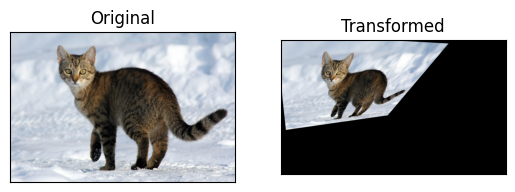

In [ ]:
pts1 = np.float32([[56,65],[368,52],[28,387],[389,390]])
pts2 = np.float32([[0,0],[300,0],[0,300],[300,300]])

perspective_tr = cv2.getPerspectiveTransform(pts1,pts2)
transformed = cv2.warpPerspective(img,perspective_tr,(np.int32(img.shape[1]*0.9),np.int32(img.shape[0]*0.8)))
plot_transformed(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cv2.cvtColor(transformed, cv2.COLOR_BGR2RGB))
